# Portfolio Assessment 2: Advanced Preprocessing & Model Development

Student Name: Le Mai Chi<br>
Student ID: 105555880 <br>
Data Name: NASA Battery Dataset <br>
Data Source: https://www.kaggle.com/datasets/patrickfleith/nasa-battery-dataset <br>
Input: cleaned discharge table produced by Portfolio Assessment 1 (`output/nasa_battery_eda_clean.csv`)

This notebook holds the code and evidence. Interpretation and justification are in the accompanying report submission, which cites the task numbers below.

## 1. Setup and Dataset Loading

In [1]:
from pathlib import Path
import sys, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PowerTransformer, OneHotEncoder
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, ConfusionMatrixDisplay

print("Python      :", sys.version.split()[0], "|", platform.platform())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("scikit-learn:", sklearn.__version__)

Python      : 3.14.5 | macOS-26.6.2-arm64-arm-64bit-Mach-O
numpy       : 2.5.3
pandas      : 3.0.6
matplotlib  : 3.11.2
seaborn     : 0.13.2
scikit-learn: 1.9.1


In [2]:
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

SEED = 42
DATA_PATH = Path("../output/nasa_battery_eda_clean.csv")
FIG_DIR = Path("output/figures")
TAB_DIR = Path("output/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

def save_table(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv", index=False)
    return df

In [3]:
df = pd.read_csv(DATA_PATH)
print("Loaded Assessment 1 table:", df.shape)
print("Batteries:", df["battery_id"].nunique())
display(df["Capacity"].describe().to_frame("Capacity (Ah)").T)

Loaded Assessment 1 table: (2750, 23)
Batteries: 34


,count,mean,std,min,25%,50%,75%,max
Capacity (Ah),2750.000,1.336,0.461,0.033,1.156,1.431,1.674,2.640


Columns are removed for the reasons established in Assessment 1 (§5):

- `capacity_class` is derived from the target (and is re-defined in Task 1).
- `n_samples` and `discharge_duration_s` nearly restate Capacity (Q ≈ I·t), so they would leak the target.
- `test_id`, `uid` and `filename` are identifiers.
- `battery_id` is kept **only** as the grouping key for battery-level splitting.

In [4]:
PREDICTORS = [
    "discharge_index", "ambient_temperature",
    "mean_voltage", "min_voltage", "max_voltage", "voltage_std", "voltage_drop",
    "mean_abs_current", "max_abs_current", "current_std",
    "mean_temperature", "max_temperature", "temperature_rise",
    "mean_abs_load_current", "mean_load_voltage",
]
EXCLUDED = ["capacity_class", "n_samples", "discharge_duration_s", "test_id", "uid", "filename"]

data = df.drop(columns=EXCLUDED)
groups = data["battery_id"]
print("Modelling table:", data.shape, "| predictors:", len(PREDICTORS))

Modelling table: (2750, 17) | predictors: 15


## 2. Task 1 – Target Variable Preparation

`Capacity` is continuous. It is discretised with **state-of-health (SOH) thresholds** relative to the 2.0 Ah rating instead of the descriptive tertiles from Assessment 1, so that each class has an engineering meaning:

The Assessment 1 tertile edges were 1.288 and 1.608 Ah (printed below). The upper threshold (1.6 Ah) almost coincides with the upper tertile edge. The lower threshold (1.4 Ah) lies 0.112 Ah above the lower tertile edge, so `EOL` is larger than a tertile. Exact class balance was deliberately not prioritised over engineering meaning.

In [5]:
RATED_AH = 2.0
BINS = [-np.inf, 1.4, 1.6, np.inf]
CLASSES = ["EOL", "Degraded", "Healthy"]

data["health_class"] = pd.cut(data["Capacity"], bins=BINS, labels=CLASSES, right=False)
y = data["health_class"].astype(str)

tertiles = pd.qcut(data["Capacity"], q=3)
class_table = pd.DataFrame({
    "class": CLASSES,
    "capacity_range_Ah": ["< 1.40", "1.40 – 1.60", "≥ 1.60"],
    "SOH_range_%": ["< 70", "70 – 80", "≥ 80"],
    "count": [int((y == c).sum()) for c in CLASSES],
})
class_table["percent"] = (class_table["count"] / len(y) * 100).round(1)
save_table(class_table, "table_A1_class_distribution")
display(class_table)

print("Assessment 1 tertile edges (Ah):", [round(i.right, 3) for i in tertiles.cat.categories[:2]])
print("Majority/minority ratio:", round(class_table["count"].max() / class_table["count"].min(), 2))
print("Rows with Capacity < 0.2 Ah (near-zero capacities from Assessment 1, kept in EOL):", int((data["Capacity"] < 0.2).sum()))

,class,capacity_range_Ah,SOH_range_%,count,percent
0,EOL,< 1.40,< 70,1274,46.300
1,Degraded,1.40 – 1.60,70 – 80,538,19.600
2,Healthy,≥ 1.60,≥ 80,938,34.100


Assessment 1 tertile edges (Ah): [np.float64(1.288), np.float64(1.608)]
Majority/minority ratio: 2.37
Rows with Capacity < 0.2 Ah (near-zero capacities from Assessment 1, kept in EOL): 187


The classes are moderately imbalanced: `Degraded` is the narrowest SOH band and holds the fewest rows. All Decision Tree and SVM classifiers therefore use `class_weight="balanced"` (the majority-class baseline in Task 10 has no class weights), and **macro-F1** is the primary metric, with balanced accuracy reported alongside plain accuracy.

*Figure 1. Capacity distribution with SOH thresholds and resulting class counts*

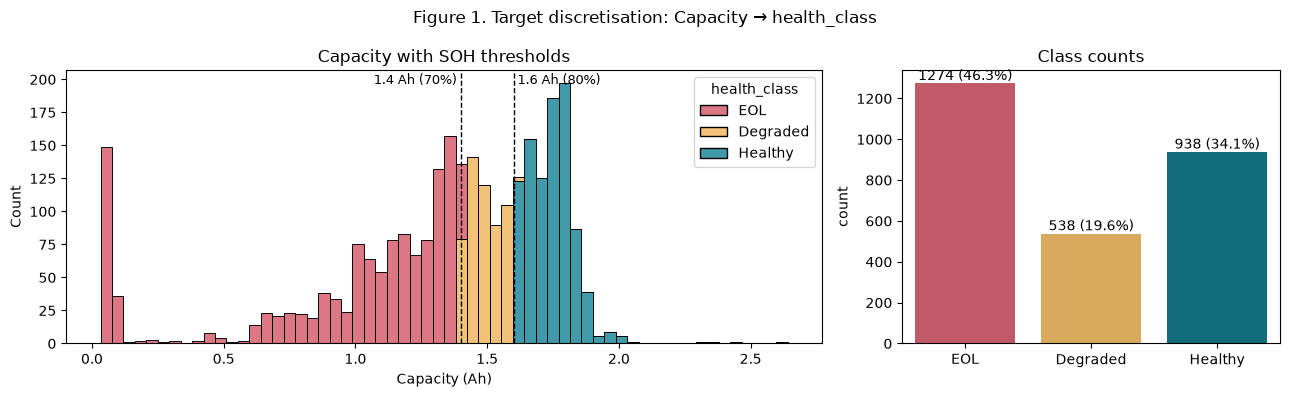

In [6]:
palette = dict(zip(CLASSES, ["#d1495b", "#edae49", "#00798c"]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2, 1]})

sns.histplot(data=data, x="Capacity", hue="health_class", hue_order=CLASSES,
             palette=palette, bins=60, multiple="stack", ax=axes[0])
for t, side in zip(BINS[1:-1], ["right", "left"]):
    axes[0].axvline(t, color="black", ls="--", lw=1)
    axes[0].text(t, axes[0].get_ylim()[1] * 0.95, f" {t} Ah ({t / RATED_AH:.0%}) ", ha=side, fontsize=9)
axes[0].set_xlabel("Capacity (Ah)")
axes[0].set_title("Capacity with SOH thresholds")

sns.barplot(data=class_table, x="class", y="count", hue="class", palette=palette, legend=False, ax=axes[1])
for i, r in class_table.iterrows():
    axes[1].text(i, r["count"], f'{r["count"]} ({r["percent"]}%)', ha="center", va="bottom")
axes[1].set_title("Class counts")
axes[1].set_xlabel("")

fig.suptitle("Figure 1. Target discretisation: Capacity → health_class")
plt.tight_layout()
save_fig("figure_01_target_classes")
plt.show()

## 3. Task 2 – Feature Normalisation & Transformation

### 3.1 Battery-grouped train/test split

All preprocessing statistics must come from training data only, so the split comes first. `GroupShuffleSplit` holds out 30 % of **batteries**, which means no battery is in both sets (Assessment 1 §5). The test set is used only to report results; feature-set and model choices are made with grouped cross-validation on the training set.

In [7]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, test_idx = next(gss.split(data, y, groups))
train, test = data.iloc[train_idx].copy(), data.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

assert set(train["battery_id"]).isdisjoint(test["battery_id"]), "battery leakage"
assert set(y_test) == set(CLASSES), "a class is missing from the test set"

split_summary = pd.DataFrame({
    "batteries": [train["battery_id"].nunique(), test["battery_id"].nunique()],
    "rows": [len(train), len(test)],
    "row_share_%": [len(train) / len(data) * 100, len(test) / len(data) * 100],
}, index=["train", "test"])
display(split_summary)
display(pd.crosstab(pd.Series(np.where(data.index.isin(train.index), "train", "test"), name="split"),
                    y, normalize="index").round(3)[CLASSES])
display(pd.crosstab(np.where(data.index.isin(train.index), "train", "test"), data["ambient_temperature"]))
print("Test batteries:", sorted(test["battery_id"].unique()))

n_b = data["battery_id"].nunique()
print(f"Requested: 30 % of battery groups in the test set. sklearn rounds the test-group count up: "
      f"{test['battery_id'].nunique()} of {n_b} batteries ({test['battery_id'].nunique() / n_b:.1%}).")
print(f"Batteries hold unequal numbers of discharge cycles, so the test set has "
      f"{len(test)} of {len(data)} rows ({len(test) / len(data):.1%}).")

,batteries,rows,row_share_%
train,23,1821,66.218
test,11,929,33.782


health_class,EOL,Degraded,Healthy
split,,,
test,0.482,0.233,0.285
train,0.454,0.177,0.370


ambient_temperature,4,22,24,43,44
row_0,,,,,
test,357,80,377,80,35
train,633,40,998,80,70


Test batteries: ['B0005', 'B0029', 'B0030', 'B0033', 'B0038', 'B0042', 'B0044', 'B0047', 'B0049', 'B0050', 'B0055']
Requested: 30 % of battery groups in the test set. sklearn rounds the test-group count up: 11 of 34 batteries (32.4%).
Batteries hold unequal numbers of discharge cycles, so the test set has 929 of 2750 rows (33.8%).


- `ambient_temperature` takes only five set-point values (4, 22, 24, 43, 44 °C, Assessment 1 Figure 9), so it is an **operating regime** and is one-hot encoded.
- The other 14 predictors are continuous. Those with |skew| > 1 on the training set get a Yeo-Johnson `PowerTransformer` (which also standardises). The rest get `StandardScaler`.
- The skew is computed once on the whole training split, before cross-validation. The choice uses no class labels and no test rows, so it is a label-free design decision, not target leakage. It is not neutral, though: applying Yeo-Johnson to every continuous feature changes the tuned-SVM result (see the report, Section 6.2).
- Trees do not need scaling, but SVM and PCA do, so one preprocessing factory is reused by every pipeline. It is fitted inside each training fold.

In [8]:
SKEW_LIMIT = 1.0
CAT_COLS = ["ambient_temperature"]

def split_roles(cols):
    num = [c for c in cols if c not in CAT_COLS]
    skewed = [c for c in num if abs(train[c].skew()) > SKEW_LIMIT]  # training split only
    symmetric = [c for c in num if c not in skewed]
    cat = [c for c in cols if c in CAT_COLS]
    return symmetric, skewed, cat

def make_preprocessor(cols):
    symmetric, skewed, cat = split_roles(cols)
    steps = []
    if symmetric: steps.append(("scale", StandardScaler(), symmetric))
    if skewed:    steps.append(("power", PowerTransformer(method="yeo-johnson"), skewed))
    if cat:       steps.append(("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return ColumnTransformer(steps, verbose_feature_names_out=False)

symmetric, skewed, cat = split_roles(PREDICTORS)
strategy = pd.DataFrame({
    "feature": PREDICTORS,
    "type": ["categorical (regime)" if c in cat else "continuous" for c in PREDICTORS],
    "train_skew": [np.nan if c in cat else round(train[c].skew(), 2) for c in PREDICTORS],
    "transformation": ["one-hot (5 levels)" if c in cat
                       else "Yeo-Johnson + standardise" if c in skewed
                       else "standardise (z-score)" for c in PREDICTORS],
})
save_table(strategy, "table_1_transformation_strategy")
display(strategy)

,feature,type,train_skew,transformation
0,discharge_index,continuous,0.880,standardise (z-score)
1,ambient_temperature,categorical (regime),NaN,one-hot (5 levels)
2,mean_voltage,continuous,1.070,Yeo-Johnson + standardise
3,min_voltage,continuous,-0.160,standardise (z-score)
4,max_voltage,continuous,-4.830,Yeo-Johnson + standardise
5,voltage_std,continuous,1.700,Yeo-Johnson + standardise
6,voltage_drop,continuous,0.770,standardise (z-score)
7,mean_abs_current,continuous,0.940,standardise (z-score)
8,max_abs_current,continuous,0.630,standardise (z-score)
9,current_std,continuous,1.180,Yeo-Johnson + standardise


In [9]:
pre_all = make_preprocessor(PREDICTORS).fit(train[PREDICTORS])
train_t = pd.DataFrame(pre_all.transform(train[PREDICTORS]), columns=pre_all.get_feature_names_out(), index=train.index)

num_cols = symmetric + skewed
evidence = pd.DataFrame({
    "before_mean": train[num_cols].mean(), "before_std": train[num_cols].std(), "before_skew": train[num_cols].skew(),
    "after_mean": train_t[num_cols].mean(), "after_std": train_t[num_cols].std(), "after_skew": train_t[num_cols].skew(),
}).round(3)
print("Before/after evidence on the training split:")
display(evidence)
print("One-hot columns:", [c for c in train_t.columns if c.startswith("ambient_temperature")])
_ = save_table(evidence.reset_index(names="feature"), "table_A3_before_after")

Before/after evidence on the training split:


,before_mean,before_std,before_skew,after_mean,after_std,after_skew
discharge_index,60.504,48.602,0.882,-0.000,1.000,0.882
min_voltage,2.335,0.266,-0.161,0.000,1.000,-0.161
voltage_drop,0.927,0.555,0.768,0.000,1.000,0.768
mean_abs_current,1.654,0.688,0.939,-0.000,1.000,0.939
max_abs_current,2.360,1.049,0.635,0.000,1.000,0.635
mean_temperature,26.652,13.334,-0.049,0.000,1.000,-0.049
max_temperature,33.867,15.609,-0.001,0.000,1.000,-0.001
mean_abs_load_current,1.652,0.691,0.967,-0.000,1.000,0.967
mean_load_voltage,1.926,0.813,-0.821,0.000,1.000,-0.821
mean_voltage,3.440,0.174,1.075,-0.000,1.000,-0.113


One-hot columns: ['ambient_temperature_4', 'ambient_temperature_22', 'ambient_temperature_24', 'ambient_temperature_43', 'ambient_temperature_44']


After transformation every continuous feature has mean ≈ 0 and SD ≈ 1, and the Yeo-Johnson columns have |skew| much lower than before. Ranges that differ by orders of magnitude (`discharge_index` 1–197 vs `max_voltage` ≈ 4.2 V) no longer dominate distance-based models.

*Figure A1. Skewed features before and after Yeo-Johnson*

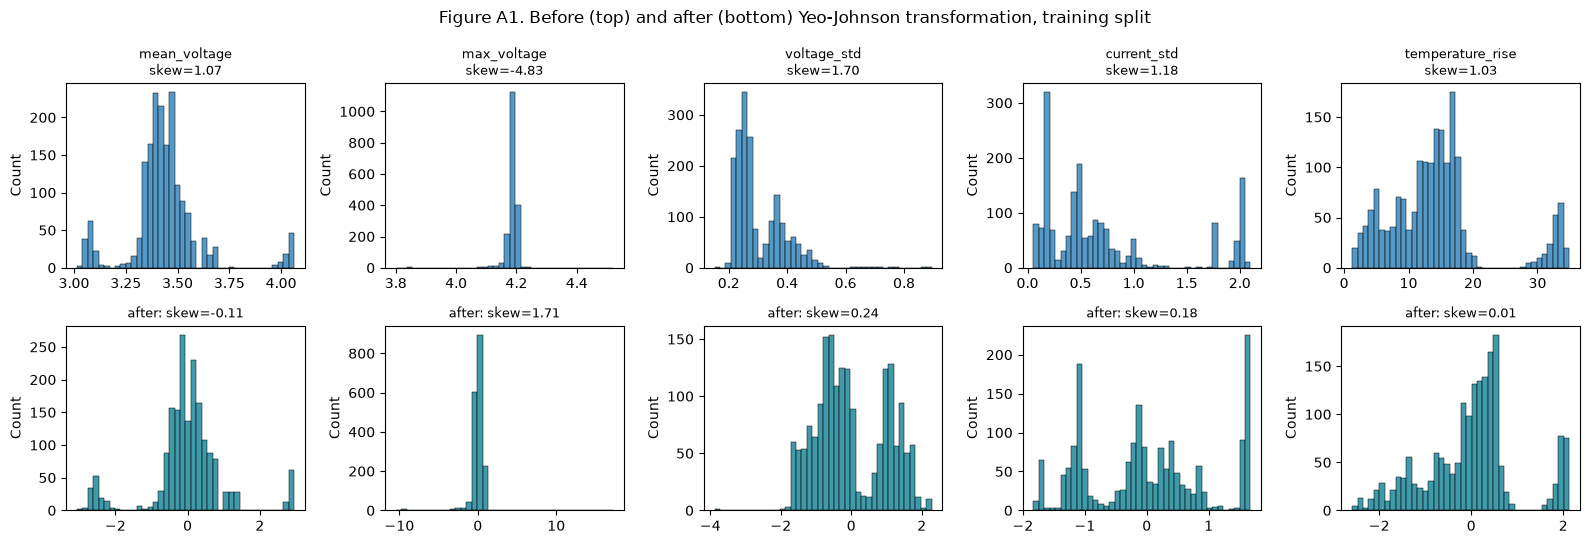

In [10]:
fig, axes = plt.subplots(2, len(skewed), figsize=(3.2 * len(skewed), 5.5))
for j, c in enumerate(skewed):
    sns.histplot(train[c], bins=40, ax=axes[0, j]); axes[0, j].set_title(f"{c}\nskew={train[c].skew():.2f}", fontsize=9)
    sns.histplot(train_t[c], bins=40, ax=axes[1, j], color="#00798c"); axes[1, j].set_title(f"after: skew={train_t[c].skew():.2f}", fontsize=9)
    axes[0, j].set_xlabel(""); axes[1, j].set_xlabel("")
fig.suptitle("Figure A1. Before (top) and after (bottom) Yeo-Johnson transformation, training split")
plt.tight_layout()
save_fig("figure_A1_transform_before_after")
plt.show()

## 4. Task 3 – Feature Engineering

Assessment 1 suggested that Capacity depends on thermal regime, discharge-curve shape and load. The new features combine existing measurements into physically interpretable quantities. None of them uses Capacity, discharge duration or future cycles.

In [11]:
ENGINEERED = {
    "avg_power_W":         ("mean_voltage × mean_abs_current",      "Average power drawn; combines load level and voltage (Assessment 1: current regimes)."),
    "voltage_range":       ("max_voltage − min_voltage",            "Total voltage swing; summarises how deep the discharge went."),
    "voltage_sag":         ("max_voltage − mean_voltage",           "Drop from the starting voltage to the mean level; captures curve shape (voltage_std was a top-3 correlate)."),
    "temp_above_ambient":  ("mean_temperature − ambient_temperature", "Self-heating relative to the chamber; separates cell heating from the set-point."),
    "heating_per_amp":     ("temperature_rise / mean_abs_current",  "Temperature rise per ampere; a rough proxy for internal resistance (I²R heating)."),
    "log_discharge_index": ("log(1 + discharge_index)",             "Compresses the right-skewed cycle count; early cycles are most informative about ageing."),
}

def add_engineered(frame):
    f = frame.copy()
    f["avg_power_W"] = f["mean_voltage"] * f["mean_abs_current"]
    f["voltage_range"] = f["max_voltage"] - f["min_voltage"]
    f["voltage_sag"] = f["max_voltage"] - f["mean_voltage"]
    f["temp_above_ambient"] = f["mean_temperature"] - f["ambient_temperature"]
    f["heating_per_amp"] = f["temperature_rise"] / f["mean_abs_current"]
    f["log_discharge_index"] = np.log1p(f["discharge_index"])
    return f

data, train, test = add_engineered(data), add_engineered(train), add_engineered(test)
ENG = list(ENGINEERED)
display(train[ENG].describe().T)

,count,mean,std,min,25%,50%,75%,max
avg_power_W,1821.000,5.648,2.319,0.917,3.638,5.967,6.680,13.441
voltage_range,1821.000,1.850,0.269,1.148,1.567,1.807,2.065,2.531
voltage_sag,1821.000,0.744,0.170,0.135,0.704,0.758,0.805,1.169
temp_above_ambient,1821.000,8.045,3.345,0.008,6.072,7.890,9.534,19.009
heating_per_amp,1821.000,9.323,4.653,0.632,6.120,8.209,10.722,22.617
log_discharge_index,1821.000,3.712,1.027,0.693,3.091,3.871,4.522,5.288


In [12]:
# Correlations on the training split only
all_feats = PREDICTORS + ENG
corr = train[all_feats + ["Capacity"]].corr()
target_r = corr["Capacity"].drop("Capacity")

eng_table = pd.DataFrame({
    "feature": ENG,
    "formula": [ENGINEERED[f][0] for f in ENG],
    "rationale": [ENGINEERED[f][1] for f in ENG],
    "r_with_Capacity": [round(target_r[f], 3) for f in ENG],
    "most_similar_feature": [corr.loc[f, [c for c in all_feats if c != f]].abs().idxmax() for f in ENG],
    "max_abs_r_with_other": [round(corr.loc[f, [c for c in all_feats if c != f]].abs().max(), 3) for f in ENG],
})
eng_table["redundant_(>0.95)"] = eng_table["max_abs_r_with_other"] > 0.95
save_table(eng_table, "table_2_engineered_features")
display(eng_table)

,feature,formula,rationale,r_with_Capacity,most_similar_feature,max_abs_r_with_other,redundant_(>0.95)
0,avg_power_W,mean_voltage × mean_abs_current,Average power drawn; combines load level and v...,0.506,mean_abs_load_current,0.996,True
1,voltage_range,max_voltage − min_voltage,Total voltage swing; summarises how deep the d...,-0.244,min_voltage,0.995,True
2,voltage_sag,max_voltage − mean_voltage,Drop from the starting voltage to the mean lev...,0.142,mean_voltage,0.987,True
3,temp_above_ambient,mean_temperature − ambient_temperature,Self-heating relative to the chamber; separate...,0.206,temperature_rise,0.952,True
4,heating_per_amp,temperature_rise / mean_abs_current,Temperature rise per ampere; a rough proxy for...,-0.314,mean_load_voltage,0.701,False
5,log_discharge_index,log(1 + discharge_index),Compresses the right-skewed cycle count; early...,-0.047,discharge_index,0.882,False


The modelling target is `health_class`, so each engineered feature is also checked against the three classes on the training split: median [Q1, Q3] per class and an effect size (Kruskal-Wallis H divided by n − 1, in [0, 1]). Rows are repeated measurements of 23 batteries, so no p-values are reported.

In [13]:
from scipy.stats import kruskal

rows = []
for f in ENG:
    groups_f = [train.loc[y_train == c, f] for c in CLASSES]
    H = kruskal(*groups_f).statistic
    rows.append({"feature": f,
                 **{c: f"{g.median():.2f} [{g.quantile(.25):.2f}, {g.quantile(.75):.2f}]" for c, g in zip(CLASSES, groups_f)},
                 "effect_size": round(H / (len(train) - 1), 3)})
by_class = save_table(pd.DataFrame(rows).sort_values("effect_size", ascending=False), "table_2b_engineered_by_class")
display(by_class)

,feature,EOL,Degraded,Healthy,effect_size
0,avg_power_W,"5.66 [3.24, 5.91]","6.26 [6.03, 6.50]","6.83 [6.27, 6.90]",0.360
2,voltage_sag,"0.80 [0.77, 0.84]","0.73 [0.71, 0.76]","0.71 [0.65, 0.75]",0.267
4,heating_per_amp,"9.49 [6.83, 15.38]","9.00 [8.07, 9.57]","6.36 [5.15, 7.84]",0.187
5,log_discharge_index,"4.03 [3.33, 4.57]","4.41 [3.62, 4.70]","3.40 [2.77, 4.06]",0.085
1,voltage_range,"1.99 [1.70, 2.17]","1.94 [1.74, 2.06]","1.73 [1.53, 1.87]",0.040
3,temp_above_ambient,"7.05 [5.16, 9.93]","8.64 [7.15, 9.42]","7.79 [6.77, 8.86]",0.026


In [14]:
# Multicollinearity: VIF = 1 / (1 - R²) of each feature regressed on the others (training split)
def vif(frame):
    X = frame.to_numpy(float)
    out = {}
    for i, c in enumerate(frame.columns):
        others = np.delete(X, i, axis=1)
        A = np.column_stack([np.ones(len(X)), others])
        coef, *_ = np.linalg.lstsq(A, X[:, i], rcond=None)
        resid = X[:, i] - A @ coef
        r2 = 1 - resid.var() / X[:, i].var()
        out[c] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(out)

vif_orig = vif(train[PREDICTORS])
vif_all = vif(train[all_feats])
print("Features with VIF > 10 — originals only:", int((vif_orig > 10).sum()), "of", len(PREDICTORS))
print("Features with VIF > 10 — originals + engineered:", int((vif_all > 10).sum()), "of", len(all_feats))
display(vif_all.sort_values(ascending=False).round(1).to_frame("VIF").T)

Features with VIF > 10 — originals only: 9 of 15
Features with VIF > 10 — originals + engineered: 17 of 21


,mean_temperature,temp_above_ambient,ambient_temperature,voltage_sag,voltage_range,max_voltage,min_voltage,mean_voltage,mean_abs_load_current,mean_abs_current,avg_power_W,max_temperature,temperature_rise,max_abs_current,current_std,mean_load_voltage,heating_per_amp,discharge_index,log_discharge_index,voltage_std,voltage_drop
VIF,inf,inf,inf,inf,inf,inf,inf,inf,13380.300,12337.400,1297.900,1145.700,129.900,34.200,30.300,20.300,16.900,5.500,5.300,4.600,3.600


*Figure 2. Correlation of original and engineered features with Capacity (training split)*

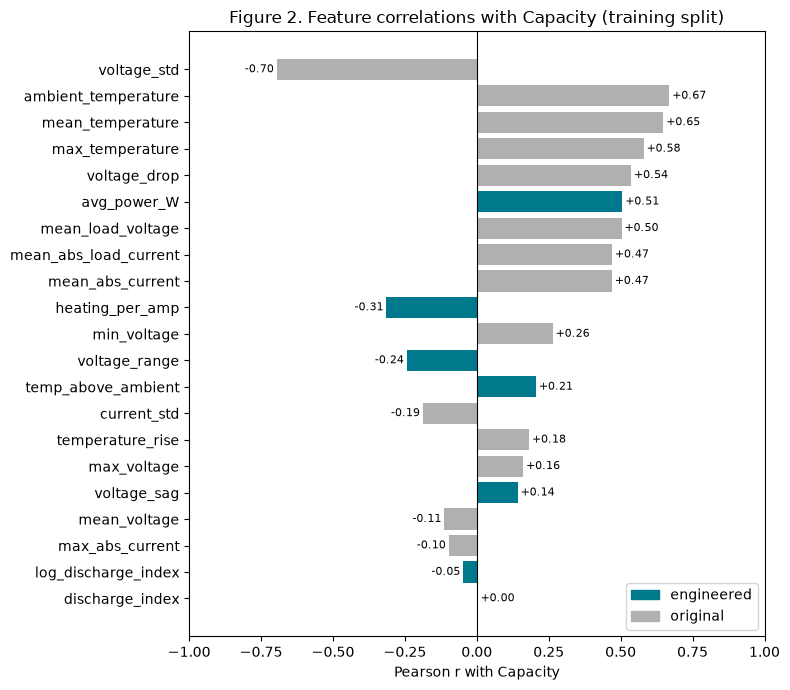

In [15]:
r_plot = target_r.sort_values(key=abs, ascending=True).to_frame("r")
r_plot["kind"] = np.where(r_plot.index.isin(ENG), "engineered", "original")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(r_plot.index, r_plot["r"], color=r_plot["kind"].map({"engineered": "#00798c", "original": "#b0b0b0"}))
ax.axvline(0, color="black", lw=0.8)
for i, v in enumerate(r_plot["r"]):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.set_xlabel("Pearson r with Capacity")
ax.set_xlim(-1, 1)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#00798c", label="engineered"), Patch(color="#b0b0b0", label="original")], loc="lower right")
ax.set_title("Figure 2. Feature correlations with Capacity (training split)")
plt.tight_layout()
save_fig("figure_02_feature_correlations")
plt.show()

## 5. Task 4 – Decision Tree Modelling

Five feature sets are compared with the same tree (`random_state=42`, `class_weight="balanced"`, default depth) and the same battery-grouped split. Each set is scored on the 30 % held-out batteries, as the task requires, **and** with 5-fold `StratifiedGroupKFold` on the training batteries. The CV score is what the later SVM experiments use to pick a feature set, so the test set never drives a choice.

**Feature set definitions**

- FS1 uses the original features; FS2 is FS1 normalised.
- FS3 adds the engineered features to FS1.
- FS4 is the non-redundant subset recommended in Assessment 1 §5: one temperature, `voltage_std`, one current, `voltage_drop` and `discharge_index`.
- FS5 adds the engineered features to FS4 and is normalised, after dropping any engineered feature with |r| > 0.95 to a feature already in the set.

In [16]:
FS4_COLS = ["ambient_temperature", "voltage_std", "mean_abs_current", "voltage_drop", "discharge_index"]

fs5_cols = list(FS4_COLS)
for f in ENG:
    if corr.loc[f, fs5_cols].abs().max() <= 0.95:
        fs5_cols.append(f)

FEATURE_SETS = {
    "FS1": dict(cols=PREDICTORS,       scaled=False, desc="All 15 original predictors (raw)"),
    "FS2": dict(cols=PREDICTORS,       scaled=True,  desc="All 15 original predictors, normalised + one-hot regime"),
    "FS3": dict(cols=PREDICTORS + ENG, scaled=False, desc="Original + 6 engineered features (raw)"),
    "FS4": dict(cols=FS4_COLS,         scaled=False, desc="Selected non-redundant originals (Assessment 1 §5)"),
    "FS5": dict(cols=fs5_cols,         scaled=True,  desc="Selected + non-redundant engineered, normalised"),
}
for fs in FEATURE_SETS.values():
    assert not set(fs["cols"]) & set(EXCLUDED + ["Capacity", "battery_id", "health_class"]), "leaky column"

fs_table = pd.DataFrame([
    {"set": k, "description": v["desc"], "n_features": len(v["cols"]),
     "preprocessing": "make_preprocessor (scale / Yeo-Johnson / one-hot)" if v["scaled"] else "none (raw values)",
     "features": ", ".join(v["cols"])}
    for k, v in FEATURE_SETS.items()
])
save_table(fs_table, "table_3_feature_sets")
display(fs_table)

,set,description,n_features,preprocessing,features
0,FS1,All 15 original predictors (raw),15,none (raw values),"discharge_index, ambient_temperature, mean_vol..."
1,FS2,"All 15 original predictors, normalised + one-h...",15,make_preprocessor (scale / Yeo-Johnson / one-hot),"discharge_index, ambient_temperature, mean_vol..."
2,FS3,Original + 6 engineered features (raw),21,none (raw values),"discharge_index, ambient_temperature, mean_vol..."
3,FS4,Selected non-redundant originals (Assessment 1...,5,none (raw values),"ambient_temperature, voltage_std, mean_abs_cur..."
4,FS5,"Selected + non-redundant engineered, normalised",10,make_preprocessor (scale / Yeo-Johnson / one-hot),"ambient_temperature, voltage_std, mean_abs_cur..."


In [17]:
CV = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

def scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro")}

def evaluate(model, cols):
    """Grouped 5-fold CV on the training batteries, then a fit on all training rows scored on the held-out batteries."""
    cv = cross_validate(model, train[cols], y_train, groups=g_train, cv=CV,
                        scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"})
    model.fit(train[cols], y_train)
    pred = model.predict(test[cols])
    return {"cv_macro_f1_mean": cv["test_macro_f1"].mean(), "cv_macro_f1_sd": cv["test_macro_f1"].std(),
            "cv_accuracy_mean": cv["test_accuracy"].mean(),
            **{f"test_{k}": v for k, v in scores(y_test, pred).items()}}, model, pred

def build_tree(fs):
    tree = DecisionTreeClassifier(random_state=SEED, class_weight="balanced")
    return Pipeline([("pre", make_preprocessor(fs["cols"])), ("model", tree)]) if fs["scaled"] else tree

dt_results, dt_models, dt_preds = {}, {}, {}

### 5.1 Feature Set 1 – all original features (raw)

In [18]:
res, dt_models["FS1"], dt_preds["FS1"] = evaluate(build_tree(FEATURE_SETS["FS1"]), FEATURE_SETS["FS1"]["cols"])
dt_results["FS1"] = res
display(pd.Series(res).round(3).to_frame("FS1").T)

,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
FS1,0.667,0.086,0.763,0.822,0.811,0.805


### 5.2 Feature Set 2 – all original features, normalised

In [19]:
res, dt_models["FS2"], dt_preds["FS2"] = evaluate(build_tree(FEATURE_SETS["FS2"]), FEATURE_SETS["FS2"]["cols"])
dt_results["FS2"] = res
display(pd.Series(res).round(3).to_frame("FS2").T)

,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
FS2,0.616,0.066,0.734,0.829,0.818,0.812


### 5.3 Feature Set 3 – original + engineered features

In [20]:
res, dt_models["FS3"], dt_preds["FS3"] = evaluate(build_tree(FEATURE_SETS["FS3"]), FEATURE_SETS["FS3"]["cols"])
dt_results["FS3"] = res
display(pd.Series(res).round(3).to_frame("FS3").T)

,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
FS3,0.548,0.128,0.652,0.781,0.764,0.761


### 5.4 Feature Set 4 – selected non-redundant features

In [21]:
res, dt_models["FS4"], dt_preds["FS4"] = evaluate(build_tree(FEATURE_SETS["FS4"]), FEATURE_SETS["FS4"]["cols"])
dt_results["FS4"] = res
display(pd.Series(res).round(3).to_frame("FS4").T)

,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
FS4,0.641,0.101,0.762,0.849,0.822,0.825


### 5.5 Feature Set 5 – selected + engineered, normalised

In [22]:
res, dt_models["FS5"], dt_preds["FS5"] = evaluate(build_tree(FEATURE_SETS["FS5"]), FEATURE_SETS["FS5"]["cols"])
dt_results["FS5"] = res
display(pd.Series(res).round(3).to_frame("FS5").T)

,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
FS5,0.554,0.080,0.674,0.892,0.865,0.874


## 6. Task 5 – Decision Tree Comparison

In [23]:
dt_table = pd.DataFrame(dt_results).T.reset_index(names="set")
dt_table.insert(1, "n_features", [len(FEATURE_SETS[s]["cols"]) for s in dt_table["set"]])
dt_table.insert(2, "tree_depth", [(m[-1] if isinstance(m, Pipeline) else m).get_depth() for m in dt_models.values()])
dt_table = dt_table.round(3)
save_table(dt_table, "table_4_decision_tree_comparison")
display(dt_table)

BEST_FS = dt_table.loc[dt_table["cv_macro_f1_mean"].idxmax(), "set"]
print("Best feature set by grouped-CV macro-F1:", BEST_FS, "->", FEATURE_SETS[BEST_FS]["desc"])

,set,n_features,tree_depth,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
0,FS1,15,10,0.667,0.086,0.763,0.822,0.811,0.805
1,FS2,15,9,0.616,0.066,0.734,0.829,0.818,0.812
2,FS3,21,11,0.548,0.128,0.652,0.781,0.764,0.761
3,FS4,5,11,0.641,0.101,0.762,0.849,0.822,0.825
4,FS5,10,10,0.554,0.080,0.674,0.892,0.865,0.874


Best feature set by grouped-CV macro-F1: FS1 -> All 15 original predictors (raw)


*Figure 3. Decision-tree performance across the five feature sets*

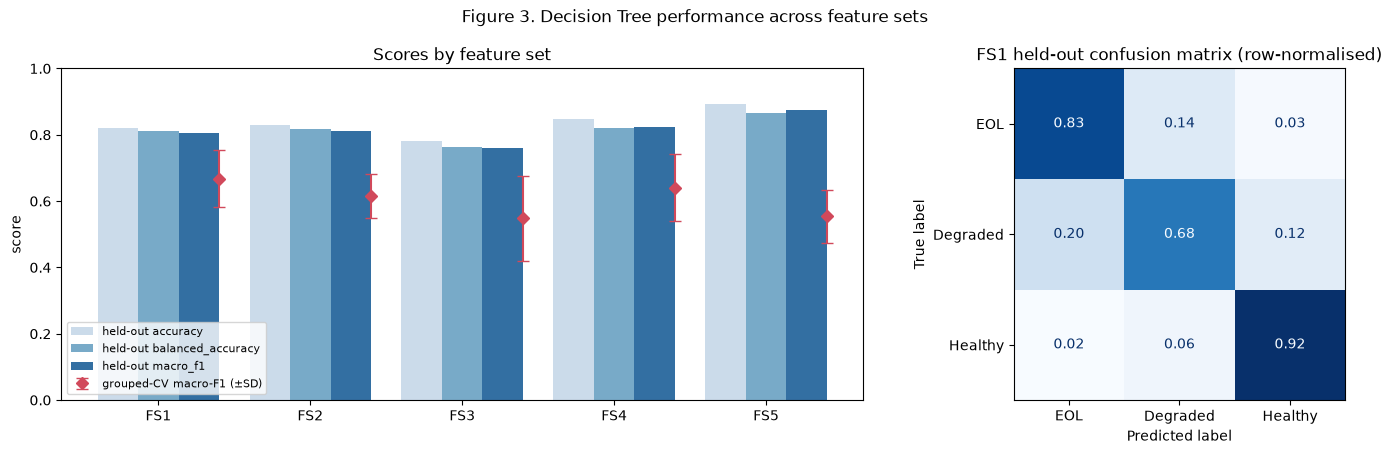

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
long = dt_table.melt(id_vars="set", value_vars=["test_accuracy", "test_balanced_accuracy", "test_macro_f1"],
                     var_name="metric", value_name="score")
long["metric"] = long["metric"].str.replace("test_", "held-out ")
sns.barplot(data=long, x="set", y="score", hue="metric", palette="Blues", ax=axes[0])
axes[0].errorbar(np.arange(len(dt_table)) + 0.4, dt_table["cv_macro_f1_mean"], yerr=dt_table["cv_macro_f1_sd"],
                 fmt="D", color="#d1495b", capsize=4, label="grouped-CV macro-F1 (±SD)")
axes[0].set_ylim(0, 1); axes[0].set_xlabel(""); axes[0].legend(loc="lower left", fontsize=8)
axes[0].set_title("Scores by feature set")

ConfusionMatrixDisplay.from_predictions(y_test, dt_preds[BEST_FS], labels=CLASSES, cmap="Blues",
                                        normalize="true", values_format=".2f", ax=axes[1], colorbar=False)
axes[1].set_title(f"{BEST_FS} held-out confusion matrix (row-normalised)")
fig.suptitle("Figure 3. Decision Tree performance across feature sets")
plt.tight_layout()
save_fig("figure_03_decision_tree_performance")
plt.show()

In [25]:
best_tree = dt_models[BEST_FS]
best_tree = best_tree[-1] if isinstance(best_tree, Pipeline) else best_tree
names = dt_models[BEST_FS][0].get_feature_names_out() if isinstance(dt_models[BEST_FS], Pipeline) else FEATURE_SETS[BEST_FS]["cols"]
display(pd.Series(best_tree.feature_importances_, index=names).sort_values(ascending=False).head(8).round(3).to_frame("importance").T)

,voltage_drop,discharge_index,mean_abs_current,voltage_std,ambient_temperature,max_temperature,mean_voltage,mean_temperature
importance,0.340,0.223,0.116,0.095,0.083,0.062,0.049,0.015


## 7. Task 6 – SVM + 5-Fold Cross-Validation

The SVM uses the feature columns of the best decision-tree set. Unlike trees, SVMs are distance-based, so the preprocessing pipeline is always applied. Folds are battery-grouped and stratified, and the scaler is refit inside each fold.

In [26]:
SVM_COLS = FEATURE_SETS[BEST_FS]["cols"]

def svm_pipeline(*middle, **svc_kw):
    return Pipeline([("pre", make_preprocessor(SVM_COLS)), *middle,
                     ("model", SVC(class_weight="balanced", random_state=SEED, **svc_kw))])

final_results, final_preds = {}, {}

svm_default = svm_pipeline()
cv_raw = cross_validate(svm_default, train[SVM_COLS], y_train, groups=g_train, cv=CV,
                        scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"})
display(pd.DataFrame({"fold": range(1, 6), "macro_f1": cv_raw["test_macro_f1"], "accuracy": cv_raw["test_accuracy"]}).round(3).T)

final_results["SVM (default RBF)"], _, final_preds["SVM (default RBF)"] = evaluate(svm_default, SVM_COLS)
display(pd.Series(final_results["SVM (default RBF)"]).round(3).to_frame("SVM default").T)

,0,1,2,3,4
fold,1.000,2.000,3.000,4.000,5.000
macro_f1,0.733,0.790,0.608,0.511,0.692
accuracy,0.762,0.812,0.860,0.683,0.674


,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
SVM default,0.667,0.098,0.758,0.825,0.790,0.796


## 8. Task 7 – Hyperparameter Tuning

`GridSearchCV` runs on the same grouped 5-fold split and optimises macro-F1. The grid covers both RBF and linear kernels.

In [27]:
C_GRID = [0.1, 1, 10, 100]
GAMMA_GRID = ["scale", 0.01, 0.1, 1]
svm_grid = [
    {"model__kernel": ["rbf"], "model__C": C_GRID, "model__gamma": GAMMA_GRID},
    {"model__kernel": ["linear"], "model__C": C_GRID},
]

def tune(pipe, grid):
    gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1_macro", n_jobs=-1)
    gs.fit(train[SVM_COLS], y_train, groups=g_train)
    return gs

gs_svm = tune(svm_pipeline(), svm_grid)
print("Best parameters:", gs_svm.best_params_)
print("Best grouped-CV macro-F1:", round(gs_svm.best_score_, 3))

final_results["SVM tuned"], _, final_preds["SVM tuned"] = evaluate(gs_svm.best_estimator_, SVM_COLS)
display(pd.Series(final_results["SVM tuned"]).round(3).to_frame("SVM tuned").T)

Best parameters: {'model__C': 1, 'model__kernel': 'linear'}
Best grouped-CV macro-F1: 0.753


,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
SVM tuned,0.753,0.056,0.804,0.777,0.744,0.748


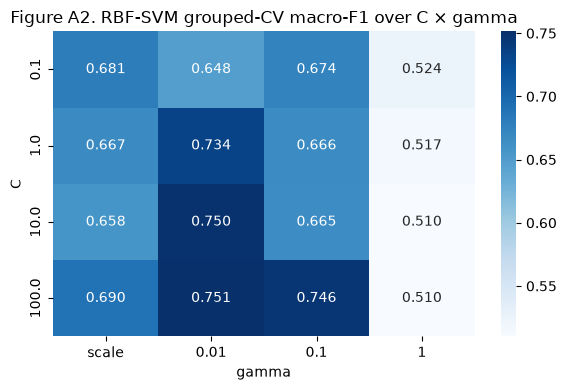

In [28]:
cvres = pd.DataFrame(gs_svm.cv_results_)
rbf = cvres[cvres["param_model__kernel"] == "rbf"].copy()
rbf["gamma"] = rbf["param_model__gamma"].astype(str)
heat = rbf.pivot_table(index="param_model__C", columns="gamma", values="mean_test_score")[["scale", "0.01", "0.1", "1"]]
plt.figure(figsize=(6, 4))
sns.heatmap(heat, annot=True, fmt=".3f", cmap="Blues")
plt.title("Figure A2. RBF-SVM grouped-CV macro-F1 over C × gamma")
plt.ylabel("C"); plt.xlabel("gamma")
plt.tight_layout()
save_fig("figure_A2_svm_grid")
plt.show()

## 9. Task 8 – Feature Selection

`SelectKBest` with mutual information is placed **inside** the pipeline, after preprocessing, so that feature scores are computed on each training fold only. `k` is tuned jointly with the SVM hyperparameters.

*Caveat.* `mutual_info_classif` receives a dense matrix, so its default treats the one-hot temperature columns as continuous. Flagging them as discrete changes their scores by at most 0.02 and keeps the same 12 inputs on the full training split, but the grid search then picks different SVM parameters (CV 0.778, held-out macro-F1 0.779 in a sensitivity run). The report states this limitation.

In [29]:
n_transformed = make_preprocessor(SVM_COLS).fit(train[SVM_COLS]).get_feature_names_out().size
# "all" rather than a number: a fold can lack a rare temperature level, giving one fewer one-hot column
K_GRID = [k for k in [3, 5, 8, 10, 12] if k < n_transformed] + ["all"]
mi = lambda X, y: mutual_info_classif(X, y, random_state=SEED)

fs_grid = [{**g, "select__k": K_GRID} for g in svm_grid]
gs_fs = tune(svm_pipeline(("select", SelectKBest(mi))), fs_grid)
print("Transformed features available:", n_transformed, "| k grid:", K_GRID)
print("Best parameters:", gs_fs.best_params_)
print("Best grouped-CV macro-F1:", round(gs_fs.best_score_, 3))

final_results["SVM tuned + feature selection"], fs_model, final_preds["SVM tuned + feature selection"] = evaluate(gs_fs.best_estimator_, SVM_COLS)
display(pd.Series(final_results["SVM tuned + feature selection"]).round(3).to_frame("SVM + selection").T)

Transformed features available: 19 | k grid: [3, 5, 8, 10, 12, 'all']
Best parameters: {'model__C': 10, 'model__gamma': 0.1, 'model__kernel': 'rbf', 'select__k': 12}
Best grouped-CV macro-F1: 0.798


,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
SVM + selection,0.798,0.129,0.865,0.829,0.820,0.813


In [30]:
sel = fs_model.named_steps["select"]
selected = pd.DataFrame({"feature": fs_model.named_steps["pre"].get_feature_names_out(),
                         "mutual_info": sel.scores_, "selected": sel.get_support()}).sort_values("mutual_info", ascending=False)
display(save_table(selected.round(3), "table_5b_mutual_information"))

,feature,mutual_info,selected
8,mean_load_voltage,0.807,True
2,voltage_drop,0.639,True
3,mean_abs_current,0.633,True
6,max_temperature,0.599,True
7,mean_abs_load_current,0.595,True
5,mean_temperature,0.575,True
12,current_std,0.478,True
9,mean_voltage,0.455,True
11,voltage_std,0.449,True
13,temperature_rise,0.384,True


## 10. Task 9 – PCA / Dimensionality Reduction

`PCA` follows standardisation inside the pipeline. The variance curve below is descriptive (training split), and `n_components` is tuned together with the SVM.

Components for 95% variance: 8 of 19


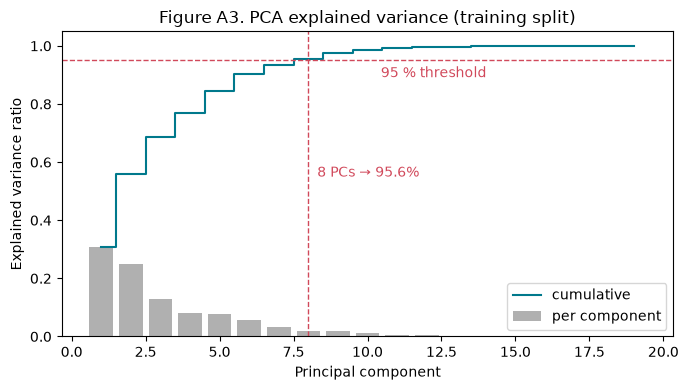

Variance explained: 5 PCs 84.6%, 8 PCs 95.6%


In [31]:
Z = make_preprocessor(SVM_COLS).fit_transform(train[SVM_COLS])
pca_full = PCA(random_state=SEED).fit(Z)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"Components for 95% variance: {n95} of {Z.shape[1]}")

plt.figure(figsize=(7, 4))
plt.bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, color="#b0b0b0", label="per component")
plt.step(range(1, len(cum) + 1), cum, where="mid", color="#00798c", label="cumulative")
plt.axhline(0.95, ls="--", color="#d1495b", lw=1); plt.axvline(n95, ls="--", color="#d1495b", lw=1)
plt.text(n95 + 0.3, 0.55, f"{n95} PCs → {cum[n95 - 1]:.1%}", color="#d1495b")
plt.text(Z.shape[1] * 0.55, 0.93, "95 % threshold", color="#d1495b", va="top")
plt.xlabel("Principal component"); plt.ylabel("Explained variance ratio"); plt.legend()
plt.title("Figure A3. PCA explained variance (training split)")
plt.tight_layout()
save_fig("figure_A3_pca_variance")
plt.show()
print(f"Variance explained: 5 PCs {cum[4]:.1%}, {n95} PCs {cum[n95 - 1]:.1%}")

In [32]:
PC_GRID = sorted({p for p in [2, 3, 5, 8, n95] if p <= Z.shape[1]})
pca_grid = [{**g, "pca__n_components": PC_GRID} for g in svm_grid]
gs_pca = tune(svm_pipeline(("pca", PCA(random_state=SEED))), pca_grid)
print("Component grid:", PC_GRID)
print("Best parameters:", gs_pca.best_params_)
print("Best grouped-CV macro-F1:", round(gs_pca.best_score_, 3))

final_results["SVM tuned + PCA"], _, final_preds["SVM tuned + PCA"] = evaluate(gs_pca.best_estimator_, SVM_COLS)
display(pd.Series(final_results["SVM tuned + PCA"]).round(3).to_frame("SVM + PCA").T)

Component grid: [2, 3, 5, 8]
Best parameters: {'model__C': 1, 'model__gamma': 0.01, 'model__kernel': 'rbf', 'pca__n_components': 5}
Best grouped-CV macro-F1: 0.767


,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
SVM + PCA,0.767,0.091,0.823,0.764,0.732,0.726


In [33]:
from sklearn.base import clone

# Same tuned SVM parameters, but the number of components set by the 95 % variance rule (reference, not in Table 5)
pca95 = clone(gs_pca.best_estimator_).set_params(pca__n_components=n95)
res95, _, _ = evaluate(pca95, SVM_COLS)
display(pd.Series(res95).round(3).to_frame(f"PCA {n95} PCs (95 % variance)").T)

,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1
PCA 8 PCs (95 % variance),0.731,0.056,0.787,0.801,0.778,0.775


## 11. Task 10 – Final Model Comparison

A majority-class baseline and the best decision tree are added so that each improvement can be judged against a reference. All rows use the same grouped CV on the training batteries and the same held-out batteries.

In [34]:
base_res, _, base_pred = evaluate(DummyClassifier(strategy="most_frequent"), SVM_COLS)
ordered = {"Baseline (majority class)": base_res, f"Decision Tree ({BEST_FS})": dt_results[BEST_FS], **final_results}
final_preds = {"Baseline (majority class)": base_pred, f"Decision Tree ({BEST_FS})": dt_preds[BEST_FS], **final_preds}

final_table = pd.DataFrame(ordered).T.reset_index(names="model").round(3)
final_table["n_inputs"] = ["–", len(FEATURE_SETS[BEST_FS]["cols"]), n_transformed, n_transformed,
                           n_transformed if gs_fs.best_params_["select__k"] == "all" else gs_fs.best_params_["select__k"], gs_pca.best_params_["pca__n_components"]]
final_table["key_settings"] = [
    "predicts most frequent class",
    "default depth, class_weight=balanced",
    "RBF, C=1, gamma=scale",
    ", ".join(f"{k.split('__')[1]}={v}" for k, v in gs_svm.best_params_.items()),
    ", ".join(f"{k.split('__')[1]}={v}" for k, v in gs_fs.best_params_.items()),
    ", ".join(f"{k.split('__')[1]}={v}" for k, v in gs_pca.best_params_.items()),
]
save_table(final_table, "table_5_final_comparison")
display(final_table)

BEST_MODEL = final_table.iloc[1:].sort_values("cv_macro_f1_mean", ascending=False)["model"].iloc[0]
print("Selected model (highest grouped-CV macro-F1):", BEST_MODEL)

,model,cv_macro_f1_mean,cv_macro_f1_sd,cv_accuracy_mean,test_accuracy,test_balanced_accuracy,test_macro_f1,n_inputs,key_settings
0,Baseline (majority class),0.211,0.019,0.464,0.482,0.333,0.217,–,predicts most frequent class
1,Decision Tree (FS1),0.667,0.086,0.763,0.822,0.811,0.805,15,"default depth, class_weight=balanced"
2,SVM (default RBF),0.667,0.098,0.758,0.825,0.790,0.796,19,"RBF, C=1, gamma=scale"
3,SVM tuned,0.753,0.056,0.804,0.777,0.744,0.748,19,"C=1, kernel=linear"
4,SVM tuned + feature selection,0.798,0.129,0.865,0.829,0.820,0.813,12,"C=10, gamma=0.1, kernel=rbf, k=12"
5,SVM tuned + PCA,0.767,0.091,0.823,0.764,0.732,0.726,5,"C=1, gamma=0.01, kernel=rbf, n_components=5"


Selected model (highest grouped-CV macro-F1): SVM tuned + feature selection


*Note.* The CV macro-F1 of the three tuned rows is optimistic: the same grouped folds chose the parameters and report the score. The held-out columns are the external comparison. The model is selected by grouped CV, never by the held-out score.

*Figure 4. Final model comparison*

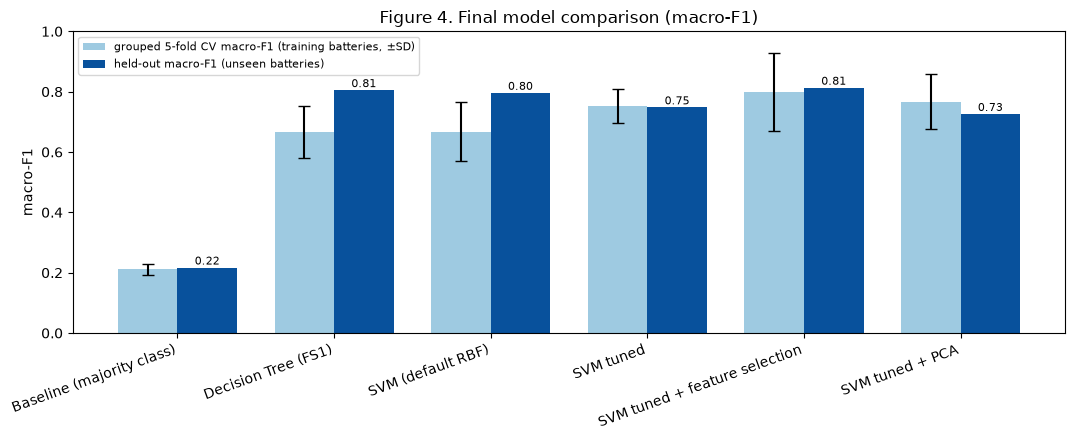

In [35]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(final_table)); w = 0.38
ax.bar(x - w / 2, final_table["cv_macro_f1_mean"], w, yerr=final_table["cv_macro_f1_sd"], capsize=4,
       color="#9ecae1", label="grouped 5-fold CV macro-F1 (training batteries, ±SD)")
ax.bar(x + w / 2, final_table["test_macro_f1"], w, color="#08519c", label="held-out macro-F1 (unseen batteries)")
for i, r in final_table.iterrows():
    ax.text(i + w / 2, r["test_macro_f1"] + 0.01, f'{r["test_macro_f1"]:.2f}', ha="center", fontsize=8)
ax.set_xticks(x, final_table["model"], rotation=20, ha="right")
ax.set_ylim(0, 1); ax.set_ylabel("macro-F1")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Figure 4. Final model comparison (macro-F1)")
plt.tight_layout()
save_fig("figure_04_final_comparison")
plt.show()

Assessment 1 committed to reporting errors by temperature group, because pooled scores can hide weak regimes.

Selected model: SVM tuned + feature selection


,ambient_temperature,rows,batteries,accuracy,macro_f1
0,4,357.000,6.000,0.950,0.724
1,22,80.000,2.000,0.812,0.812
2,24,377.000,3.000,0.695,0.706
3,43,80.000,2.000,0.888,0.470
4,44,35.000,1.000,0.943,0.500


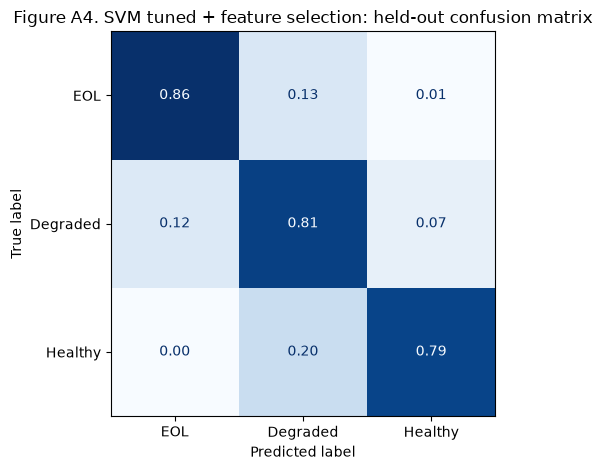

In [36]:
regime = pd.DataFrame({"ambient_temperature": test["ambient_temperature"], "y": y_test, "pred": final_preds[BEST_MODEL]})
per_temp = (regime.groupby("ambient_temperature")
            .apply(lambda g: pd.Series({"rows": len(g), "batteries": test.loc[g.index, "battery_id"].nunique(),
                                        "accuracy": accuracy_score(g["y"], g["pred"]),
                                        "macro_f1": f1_score(g["y"], g["pred"], average="macro", labels=sorted(g["y"].unique()))}),
                   include_groups=False)
            .reset_index().round(3))
save_table(per_temp, "table_A2_per_temperature")
print("Selected model:", BEST_MODEL)
display(per_temp)

ConfusionMatrixDisplay.from_predictions(y_test, final_preds[BEST_MODEL], labels=CLASSES, cmap="Blues",
                                        normalize="true", values_format=".2f", colorbar=False)
plt.title(f"Figure A4. {BEST_MODEL}: held-out confusion matrix")
plt.tight_layout()
save_fig("figure_A4_best_confusion")
plt.show()

## 12. Brief Conclusion

In [37]:
best_row = final_table.set_index("model").loc[BEST_MODEL]
dt_row = final_table.set_index("model").loc[f"Decision Tree ({BEST_FS})"]
print(f"Target: 3 SOH classes (EOL / Degraded / Healthy), {len(data)} rows from {groups.nunique()} batteries; "
      f"{test['battery_id'].nunique()} batteries held out.")
print(f"Best decision-tree feature set: {BEST_FS} (CV macro-F1 {dt_row['cv_macro_f1_mean']:.3f}, held-out {dt_row['test_macro_f1']:.3f}).")
print(f"Selected model: {BEST_MODEL} (CV macro-F1 {best_row['cv_macro_f1_mean']:.3f} ± {best_row['cv_macro_f1_sd']:.3f}, "
      f"held-out macro-F1 {best_row['test_macro_f1']:.3f}, accuracy {best_row['test_accuracy']:.3f}).")

Target: 3 SOH classes (EOL / Degraded / Healthy), 2750 rows from 34 batteries; 11 batteries held out.
Best decision-tree feature set: FS1 (CV macro-F1 0.667, held-out 0.805).
Selected model: SVM tuned + feature selection (CV macro-F1 0.798 ± 0.129, held-out macro-F1 0.813, accuracy 0.829).


All splits are by battery, so these scores estimate performance on **unseen cells**. The discussion, limitations and model choice are in the report (§7–8).